# Athena Loader Benchmark 

**Libraries under test**
1. s3DataLoader
2. PyAthena 
3. Boto3
4. DuckDB 
5. Metabase API

In [1]:
from __future__ import annotations

import os
from pathlib import Path

# --- paths ---
ROOT = Path.cwd()
if not (ROOT / "s3DataLoader-main").exists() and (ROOT.parent / "s3DataLoader-main").exists():
    ROOT = ROOT.parent
S3DL_ROOT = ROOT / "s3DataLoader-main"
RESULTS_DIR = ROOT / "benchmark_results"
RESULTS_DIR.mkdir(exist_ok=True)

# --- benchmark knobs ---
N_RUNS = 5                 # timed runs per (library, scenario)
N_WARMUP = 1               # discarded warm-up runs
ENABLE_LIBRARIES = {
    "s3dataloader_athena": True,
    "pyathena": True,
    "boto3_athena": True,
    "duckdb_s3": True,
    "metabase": True,      # auto-skips if METABASE_* env missing
}

# Date window applied to ALL scenarios so every library sees the same slice.
# Widen for larger tests; keep narrow for cheap iteration.
BENCH_START = os.getenv("BENCH_START", "2025-06-01")
BENCH_END = os.getenv("BENCH_END", "2025-06-07")

# Safety: unbounded full-table without date filter (expensive). Keep False unless intentional.
ENABLE_UNBOUNDED_FULL_TABLE = False

# Large-result target (LIMIT). Raise if the window has enough rows.
LARGE_RESULT_ROWS = int(os.getenv("BENCH_LARGE_ROWS", "1000000"))

# Chunk sizes for chunked-reading scenarios
CHUNK_SIZES = [10_000, 50_000, 100_000]

# Projected columns (adjusted after schema probe if some are missing)
PROJECTED_COLUMNS = ["visitorId", "lead", "createdAt", "project", "source"]

print("ROOT:", ROOT)
print("Window:", BENCH_START, "→", BENCH_END)
print("Results:", RESULTS_DIR)

ROOT: /Users/lekhanigam/RM Feature Analysis
Window: 2025-06-01 → 2025-06-07
Results: /Users/lekhanigam/RM Feature Analysis/benchmark_results


## 1. Setup & imports

In [2]:
import sys
import time
import uuid
import json
import math
import traceback
import tracemalloc
from dataclasses import dataclass, field, asdict
from typing import Any, Callable, Optional
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dotenv import load_dotenv

# Load env from workspace + s3DataLoader-main (later files do not override existing)
for env_path in (ROOT / ".env", S3DL_ROOT / ".env", S3DL_ROOT / "env.example"):
    if env_path.exists():
        load_dotenv(env_path, override=False)

# Defaults for DuckDB if only Athena keys are present in .env
os.environ.setdefault("S3_BUCKET", "airflow-etl-db")
os.environ.setdefault("S3_PREFIX_LEADS_DB", "production_raw_dump/leads-db")
os.environ.setdefault("AWS_REGION", "ap-south-1")

if str(S3DL_ROOT) not in sys.path:
    sys.path.insert(0, str(S3DL_ROOT))

import boto3
from botocore.config import Config as BotoConfig

try:
    import psutil
except ImportError:
    psutil = None

ATHENA_DATABASE = os.environ["ATHENA_DATABASE"].strip()
ATHENA_WORKGROUP = os.getenv("ATHENA_WORKGROUP", "").strip()
ATHENA_OUTPUT = os.getenv("ATHENA_OUTPUT_LOCATION", "").strip()
AWS_REGION = os.getenv("AWS_REGION", "ap-south-1").strip()
S3_BUCKET = os.environ["S3_BUCKET"].strip()
S3_PREFIX = os.getenv("S3_PREFIX_LEADS_DB") or os.getenv("S3_PREFIX") or "production_raw_dump/leads-db"
S3_PREFIX = S3_PREFIX.strip().strip('"').rstrip("/")

TABLE = "visitorlogs"
DATE_COL = "createdAt"

print("Athena DB:", ATHENA_DATABASE)
print("Workgroup:", ATHENA_WORKGROUP or "(account default)")
print("Output:", ATHENA_OUTPUT or "(workgroup enforced)")
print("DuckDB parquet root:", f"s3://{S3_BUCKET}/{S3_PREFIX}/{TABLE}/")

Athena DB: leadsdb-prod
Workgroup: asbl_analytics_prod
Output: s3://airflow-etl-db/athena_storage/
DuckDB parquet root: s3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/


## 2. Metric helpers

In [3]:
@dataclass
class RunMetrics:
    library: str
    scenario: str
    run_idx: int
    total_s: float
    query_s: Optional[float]
    download_s: Optional[float]
    df_create_s: Optional[float]
    rows: int
    cols: int
    peak_mem_mb: float
    cpu_percent: Optional[float]
    api_calls: int
    retries: int
    error: Optional[str] = None
    notes: str = ""


def _rss_mb() -> float:
    if psutil is None:
        return float("nan")
    return psutil.Process(os.getpid()).memory_info().rss / (1024 * 1024)


def measure_call(fn: Callable[[], Any]) -> tuple[Any, dict]:
    """Run fn once; return (result_or_None, metrics_dict)."""
    tracemalloc.start()
    mem_before = _rss_mb()
    cpu_before = psutil.Process(os.getpid()).cpu_percent(interval=None) if psutil else None
    t0 = time.perf_counter()
    err = None
    result = None
    try:
        result = fn()
    except Exception as exc:
        err = f"{type(exc).__name__}: {exc}"
        traceback.print_exc()
    total = time.perf_counter() - t0
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    mem_after = _rss_mb()
    cpu_after = psutil.Process(os.getpid()).cpu_percent(interval=0.05) if psutil else None
    peak_mb = max(peak / (1024 * 1024), (mem_after - mem_before) if not math.isnan(mem_after) else 0.0)
    return result, {
        "total_s": total,
        "peak_mem_mb": float(peak_mb),
        "cpu_percent": cpu_after,
        "error": err,
    }


def bust_cache(sql: str) -> str:
    """Append a unique comment so Athena result reuse cannot help a library."""
    return f"/* bench-{uuid.uuid4().hex} */\n{sql}"


def summarize(times: list[float]) -> dict:
    arr = np.asarray(times, dtype=float)
    return {
        "avg": float(arr.mean()) if len(arr) else float("nan"),
        "min": float(arr.min()) if len(arr) else float("nan"),
        "max": float(arr.max()) if len(arr) else float("nan"),
        "std": float(arr.std(ddof=1)) if len(arr) > 1 else 0.0,
    }


ALL_RUNS: list[RunMetrics] = []
print("Helpers ready.")

Helpers ready.


## 3. SQL builders (identical logical queries)

In [4]:
def _quote(c: str) -> str:
    if '"' in c:
        raise ValueError(c)
    return f'"{c}"'


def date_predicate(start: str = BENCH_START, end: str = BENCH_END) -> str:
    return (
        f"{_quote(DATE_COL)} >= TIMESTAMP '{start} 00:00:00' "
        f"AND {_quote(DATE_COL)} <= TIMESTAMP '{end} 23:59:59'"
    )


def build_select(
    columns: Optional[list[str]] = None,
    *,
    where: Optional[list[str]] = None,
    limit: Optional[int] = None,
    select_expr: Optional[str] = None,
    group_by: Optional[list[str]] = None,
    order_by: Optional[str] = None,
    apply_date_window: bool = True,
) -> str:
    """Build Athena SQL against visitorlogs."""
    if select_expr:
        select_sql = select_expr
    elif columns:
        select_sql = ", ".join(_quote(c) for c in columns)
    else:
        select_sql = "*"
    sql = f"SELECT {select_sql} FROM {_quote(TABLE)}"
    preds = []
    if apply_date_window:
        preds.append(date_predicate())
    if where:
        preds.extend(where)
    if preds:
        sql += " WHERE " + " AND ".join(preds)
    if group_by:
        sql += " GROUP BY " + ", ".join(_quote(c) for c in group_by)
    if order_by:
        sql += f" ORDER BY {order_by}"
    if limit is not None:
        sql += f" LIMIT {int(limit)}"
    return sql


# DuckDB reads the same parquet dump (indexed layout uses /data/).
DUCKDB_GLOB = f"s3://{S3_BUCKET}/{S3_PREFIX}/{TABLE}/data/*.parquet"


def athena_to_duckdb_sql(athena_sql: str) -> str:
    """Rewrite FROM \"visitorlogs\" → parquet_scan glob (same logical query)."""
    return athena_sql.replace(f'FROM {_quote(TABLE)}', f"FROM parquet_scan('{DUCKDB_GLOB}')")


print("Sample SQL:\n", build_select(limit=5))

Sample SQL:
 SELECT * FROM "visitorlogs" WHERE "createdAt" >= TIMESTAMP '2025-06-01 00:00:00' AND "createdAt" <= TIMESTAMP '2025-06-07 23:59:59' LIMIT 5


## 4. Library adapters

In [5]:
class Adapter:
    name: str
    supports_chunksize: bool = False

    def warmup(self) -> None:
        self.run(build_select(columns=[DATE_COL], limit=1), chunksize=None)

    def run(self, sql: str, *, chunksize: Optional[int] = None) -> tuple[pd.DataFrame, dict]:
        raise NotImplementedError


class S3DataLoaderAthenaAdapter(Adapter):
    name = "s3dataloader_athena"
    supports_chunksize = True

    def __init__(self):
        from dataSource import DataLoader
        self.loader = DataLoader(
            engine="athena",
            database=ATHENA_DATABASE,
            workgroup=ATHENA_WORKGROUP or None,
            output_location=ATHENA_OUTPUT or None,
            region=AWS_REGION,
            ctas_approach=False,
            max_cache_seconds=0,
        )

    def run(self, sql: str, *, chunksize: Optional[int] = None):
        sql = bust_cache(sql)
        meta = {"query_s": None, "download_s": None, "df_create_s": None, "api_calls": 0, "retries": 0, "notes": "awswrangler via DataLoader"}
        t0 = time.perf_counter()
        if chunksize:
            parts = []
            t_dl = time.perf_counter()
            for chunk in self.loader.read_sql(sql, chunksize=chunksize):
                parts.append(chunk)
            meta["download_s"] = time.perf_counter() - t_dl
            t_df = time.perf_counter()
            df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
            meta["df_create_s"] = time.perf_counter() - t_df
        else:
            t_q = time.perf_counter()
            df = self.loader.read_sql(sql)
            meta["query_s"] = time.perf_counter() - t_q  # includes download for this engine
            if not isinstance(df, pd.DataFrame):
                df = pd.concat(list(df), ignore_index=True)
        meta["wall_s"] = time.perf_counter() - t0
        return df, meta


class PyAthenaAdapter(Adapter):
    name = "pyathena"
    supports_chunksize = True

    def __init__(self):
        from pyathena import connect
        # Default cursor uses GetQueryResults (works when S3 result bucket is denied).
        # PandasCursor reads CSV from S3 and fails with HeadObject 403 on this account.
        kwargs = {
            "s3_staging_dir": ATHENA_OUTPUT,
            "region_name": AWS_REGION,
            "schema_name": ATHENA_DATABASE,
        }
        if ATHENA_WORKGROUP:
            kwargs["work_group"] = ATHENA_WORKGROUP
        self.conn = connect(**kwargs)

    def run(self, sql: str, *, chunksize: Optional[int] = None):
        sql = bust_cache(sql)
        meta = {"query_s": None, "download_s": None, "df_create_s": None, "api_calls": 1, "retries": 0, "notes": "default Cursor (GetQueryResults API)"}
        cur = self.conn.cursor()
        t0 = time.perf_counter()
        t_q = time.perf_counter()
        cur.execute(sql)
        meta["query_s"] = time.perf_counter() - t_q
        t_dl = time.perf_counter()
        cols = [d[0] for d in (cur.description or [])]
        if chunksize:
            parts = []
            while True:
                batch = cur.fetchmany(int(chunksize))
                if not batch:
                    break
                parts.append(pd.DataFrame(batch, columns=cols))
            meta["download_s"] = time.perf_counter() - t_dl
            t_df = time.perf_counter()
            df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=cols)
            meta["df_create_s"] = time.perf_counter() - t_df
        else:
            rows = cur.fetchall()
            meta["download_s"] = time.perf_counter() - t_dl
            t_df = time.perf_counter()
            df = pd.DataFrame(rows, columns=cols)
            meta["df_create_s"] = time.perf_counter() - t_df
        meta["wall_s"] = time.perf_counter() - t0
        return df, meta


class Boto3AthenaAdapter(Adapter):
    """Athena APIs for execution + GetQueryResults (S3 result bucket is denied on this account)."""
    name = "boto3_athena"
    supports_chunksize = True

    def __init__(self):
        from dataSource.aws_auth import create_boto3_session
        self.session = create_boto3_session(AWS_REGION)
        self.athena = self.session.client("athena", config=BotoConfig(retries={"max_attempts": 10}))
        self.api_calls = 0

    def _wait(self, qid: str) -> dict:
        while True:
            self.api_calls += 1
            resp = self.athena.get_query_execution(QueryExecutionId=qid)
            state = resp["QueryExecution"]["Status"]["State"]
            if state in {"SUCCEEDED", "FAILED", "CANCELLED"}:
                return resp
            time.sleep(0.5)

    def run(self, sql: str, *, chunksize: Optional[int] = None):
        sql = bust_cache(sql)
        self.api_calls = 0
        meta = {"query_s": None, "download_s": None, "df_create_s": None, "api_calls": 0, "retries": 0, "notes": "StartQueryExecution + GetQueryResults"}
        t0 = time.perf_counter()
        params = {
            "QueryString": sql,
            "QueryExecutionContext": {"Database": ATHENA_DATABASE},
            "ResultConfiguration": {"OutputLocation": ATHENA_OUTPUT},
        }
        if ATHENA_WORKGROUP:
            params["WorkGroup"] = ATHENA_WORKGROUP
        t_q = time.perf_counter()
        self.api_calls += 1
        qid = self.athena.start_query_execution(**params)["QueryExecutionId"]
        exec_resp = self._wait(qid)
        meta["query_s"] = time.perf_counter() - t_q
        status = exec_resp["QueryExecution"]["Status"]
        if status["State"] != "SUCCEEDED":
            raise RuntimeError(status.get("StateChangeReason", status["State"]))
        t_dl = time.perf_counter()
        columns = None
        buffer = []
        parts = []
        next_token = None
        while True:
            kwargs = {"QueryExecutionId": qid, "MaxResults": 1000}
            if next_token:
                kwargs["NextToken"] = next_token
            self.api_calls += 1
            page = self.athena.get_query_results(**kwargs)
            rows = page["ResultSet"]["Rows"]
            start = 0
            if columns is None:
                columns = [c.get("VarCharValue", "") for c in rows[0]["Data"]]
                start = 1
            for row in rows[start:]:
                buffer.append([c.get("VarCharValue") for c in row["Data"]])
                if chunksize and len(buffer) >= int(chunksize):
                    parts.append(pd.DataFrame(buffer, columns=columns))
                    buffer = []
            next_token = page.get("NextToken")
            if not next_token:
                break
        meta["download_s"] = time.perf_counter() - t_dl
        t_df = time.perf_counter()
        if buffer:
            parts.append(pd.DataFrame(buffer, columns=columns))
        df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=columns or [])
        meta["df_create_s"] = time.perf_counter() - t_df
        meta["api_calls"] = self.api_calls
        meta["wall_s"] = time.perf_counter() - t0
        return df, meta


class DuckDBS3Adapter(Adapter):
    name = "duckdb_s3"
    supports_chunksize = True

    def __init__(self):
        from dataSource import DataLoader
        self.loader = DataLoader(engine="duckdb", source="leads-db")
        # Ensure httpfs/S3 creds via underlying connection
        self.con = self.loader.backend.parquet_loader._get_connection()

    def run(self, sql: str, *, chunksize: Optional[int] = None):
        duck_sql = athena_to_duckdb_sql(sql)
        meta = {"query_s": None, "download_s": None, "df_create_s": None, "api_calls": 0, "retries": 0, "notes": f"parquet_scan {DUCKDB_GLOB}"}
        t0 = time.perf_counter()
        if chunksize:
            # OFFSET/LIMIT chunking for fair memory comparison
            parts = []
            offset = 0
            t_dl = time.perf_counter()
            while True:
                page_sql = f"SELECT * FROM ({duck_sql}) AS _q LIMIT {int(chunksize)} OFFSET {int(offset)}"
                part = self.con.execute(page_sql).df()
                if part.empty:
                    break
                parts.append(part)
                offset += len(part)
                if len(part) < chunksize:
                    break
            meta["download_s"] = time.perf_counter() - t_dl
            t_df = time.perf_counter()
            df = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
            meta["df_create_s"] = time.perf_counter() - t_df
        else:
            t_q = time.perf_counter()
            df = self.con.execute(duck_sql).df()
            meta["query_s"] = time.perf_counter() - t_q
        meta["wall_s"] = time.perf_counter() - t0
        return df, meta


class MetabaseAdapter(Adapter):
    name = "metabase"
    supports_chunksize = False

    def __init__(self):
        import requests
        self.requests = requests
        self.base = os.getenv("METABASE_URL", "").rstrip("/")
        self.user = os.getenv("METABASE_USER", "")
        self.password = os.getenv("METABASE_PASSWORD", "")
        self.database_id = os.getenv("METABASE_DATABASE_ID", "")
        self.session_token = None
        if not all([self.base, self.user, self.password, self.database_id]):
            raise RuntimeError("Metabase env not configured (METABASE_URL/USER/PASSWORD/DATABASE_ID)")
        self._login()

    def _login(self):
        r = self.requests.post(
            f"{self.base}/api/session",
            json={"username": self.user, "password": self.password},
            timeout=60,
        )
        r.raise_for_status()
        self.session_token = r.json()["id"]

    def run(self, sql: str, *, chunksize: Optional[int] = None):
        # Metabase native query — use export endpoint to reduce 2k interactive cap
        sql = bust_cache(sql)
        meta = {"query_s": None, "download_s": None, "df_create_s": None, "api_calls": 1, "retries": 0, "notes": "Metabase /api/dataset/json"}
        headers = {"X-Metabase-Session": self.session_token}
        payload = {
            "database": int(self.database_id),
            "type": "native",
            "native": {"query": sql, "template-tags": {}},
        }
        t0 = time.perf_counter()
        t_q = time.perf_counter()
        # Prefer JSON export path
        r = self.requests.post(
            f"{self.base}/api/dataset/json",
            headers={**headers, "Content-Type": "application/x-www-form-urlencoded"},
            data={"query": json.dumps(payload)},
            timeout=600,
        )
        if r.status_code >= 400:
            # fallback interactive dataset
            r = self.requests.post(
                f"{self.base}/api/dataset",
                headers={**headers, "Content-Type": "application/json"},
                json=payload,
                timeout=600,
            )
            r.raise_for_status()
            meta["query_s"] = time.perf_counter() - t_q
            data = r.json()
            cols = [c["name"] for c in data.get("data", {}).get("cols", [])]
            rows = data.get("data", {}).get("rows", [])
            t_df = time.perf_counter()
            df = pd.DataFrame(rows, columns=cols)
            meta["df_create_s"] = time.perf_counter() - t_df
            meta["notes"] += " (interactive; may be row-capped)"
        else:
            meta["query_s"] = time.perf_counter() - t_q
            t_df = time.perf_counter()
            df = pd.DataFrame(r.json())
            meta["df_create_s"] = time.perf_counter() - t_df
        meta["wall_s"] = time.perf_counter() - t0
        return df, meta


ADAPTER_CTORS = {
    "s3dataloader_athena": S3DataLoaderAthenaAdapter,
    "pyathena": PyAthenaAdapter,
    "boto3_athena": Boto3AthenaAdapter,
    "duckdb_s3": DuckDBS3Adapter,
    "metabase": MetabaseAdapter,
}

adapters: dict[str, Adapter] = {}
for name, enabled in ENABLE_LIBRARIES.items():
    if not enabled:
        continue
    try:
        adapters[name] = ADAPTER_CTORS[name]()
        print(f"[ok] {name}")
    except Exception as exc:
        print(f"[skip] {name}: {exc}")

print("Active adapters:", list(adapters))

[ok] s3dataloader_athena
[ok] pyathena
[ok] boto3_athena
[ok] duckdb_s3
[ok] metabase
Active adapters: ['s3dataloader_athena', 'pyathena', 'boto3_athena', 'duckdb_s3', 'metabase']


In [6]:
# #region agent log
# DEBUG: diagnose Athena S3 403 + Metabase skip (session 20b5bd)
import json, time
from pathlib import Path as _Path

_DBG = _Path("/Users/lekhanigam/RM Feature Analysis/.cursor/debug-20b5bd.log")

def _agent_log(hypothesis_id, location, message, data=None, run_id="pre-fix"):
    payload = {
        "sessionId": "20b5bd",
        "runId": run_id,
        "hypothesisId": hypothesis_id,
        "location": location,
        "message": message,
        "data": data or {},
        "timestamp": int(time.time() * 1000),
    }
    with _DBG.open("a") as f:
        f.write(json.dumps(payload, default=str) + "\n")
    print(f"[debug:{hypothesis_id}] {message} | {data}")

# H-C: credential whitespace / key shape (never log secrets)
_ak = os.getenv("AWS_ACCESS_KEY_ID") or ""
_sk = os.getenv("AWS_SECRET_ACCESS_KEY") or ""
_agent_log("C", "debug_diag:creds", "credential env shape", {
    "ak_len": len(_ak),
    "sk_len": len(_sk),
    "ak_has_leading_space": _ak[:1] == " ",
    "ak_has_trailing_space": _ak[-1:] == " ",
    "sk_has_leading_space": _sk[:1] == " ",
    "sk_has_trailing_space": _sk[-1:] == " ",
    "ak_prefix": _ak.strip()[:4],
    "expected_account": os.getenv("EXPECTED_AWS_ACCOUNT_ID"),
})

# H-A/B/D: identity + workgroup output + head_object on result path
_sess = boto3.Session(region_name=AWS_REGION)
if _ak.strip() and _sk.strip():
    _sess = boto3.Session(
        aws_access_key_id=_ak.strip(),
        aws_secret_access_key=_sk.strip(),
        region_name=AWS_REGION,
    )
_sts = _sess.client("sts")
_ath = _sess.client("athena")
_s3c = _sess.client("s3")

try:
    ident = _sts.get_caller_identity()
    _agent_log("A", "debug_diag:sts", "caller identity", {
        "account": ident.get("Account"),
        "arn": ident.get("Arn"),
        "account_matches_expected": ident.get("Account") == os.getenv("EXPECTED_AWS_ACCOUNT_ID"),
    })
except Exception as e:
    _agent_log("A", "debug_diag:sts", "sts failed", {"error": type(e).__name__, "msg": str(e)[:200]})

wg_out = None
try:
    wg = _ath.get_work_group(WorkGroup=ATHENA_WORKGROUP) if ATHENA_WORKGROUP else None
    cfg = (wg or {}).get("WorkGroup", {}).get("Configuration", {})
    wg_out = (cfg.get("ResultConfiguration") or {}).get("OutputLocation")
    enforce = cfg.get("EnforceWorkGroupConfiguration")
    _agent_log("B", "debug_diag:workgroup", "workgroup result config", {
        "workgroup": ATHENA_WORKGROUP,
        "wg_output": wg_out,
        "env_output": ATHENA_OUTPUT,
        "outputs_match": (wg_out or "").rstrip("/") == (ATHENA_OUTPUT or "").rstrip("/"),
        "enforce_wg_config": enforce,
    })
except Exception as e:
    _agent_log("B", "debug_diag:workgroup", "get_work_group failed", {"error": type(e).__name__, "msg": str(e)[:300]})

# Run tiny query, then HeadObject the result CSV
_qid = None
_result_uri = None
try:
    params = {
        "QueryString": f"/* debug-{int(time.time())} */\nSELECT 1 AS x",
        "QueryExecutionContext": {"Database": ATHENA_DATABASE},
        "ResultConfiguration": {"OutputLocation": ATHENA_OUTPUT},
    }
    if ATHENA_WORKGROUP:
        params["WorkGroup"] = ATHENA_WORKGROUP
    _qid = _ath.start_query_execution(**params)["QueryExecutionId"]
    while True:
        ex = _ath.get_query_execution(QueryExecutionId=_qid)["QueryExecution"]
        st = ex["Status"]["State"]
        if st in {"SUCCEEDED", "FAILED", "CANCELLED"}:
            break
        time.sleep(0.4)
    _result_uri = ex.get("ResultConfiguration", {}).get("OutputLocation")
    _agent_log("B", "debug_diag:query", "tiny query finished", {
        "state": st,
        "reason": ex.get("Status", {}).get("StateChangeReason", "")[:200],
        "result_uri": _result_uri,
        "qid": _qid,
    })
    if st == "SUCCEEDED" and _result_uri:
        _, _, rest = _result_uri.partition("s3://")
        bkt, _, key = rest.partition("/")
        try:
            head = _s3c.head_object(Bucket=bkt, Key=key)
            _agent_log("A", "debug_diag:head", "HeadObject SUCCESS", {
                "bucket": bkt,
                "key_suffix": key[-80:],
                "sse": head.get("ServerSideEncryption"),
                "sse_kms_key": bool(head.get("SSEKMSKeyId")),
                "content_length": head.get("ContentLength"),
            })
        except Exception as e:
            err = getattr(e, "response", {}) or {}
            _agent_log("A", "debug_diag:head", "HeadObject FAILED", {
                "bucket": bkt,
                "key_suffix": key[-80:],
                "error": type(e).__name__,
                "code": err.get("Error", {}).get("Code"),
                "http": err.get("ResponseMetadata", {}).get("HTTPStatusCode"),
                "msg": str(e)[:300],
            })
            # H-D: if 403, note possible KMS
            _agent_log("D", "debug_diag:kms_hint", "403 may be IAM or KMS", {
                "likely_missing_s3_get": True,
                "check_kms_if_bucket_uses_sse_kms": True,
            })
except Exception as e:
    _agent_log("A", "debug_diag:query", "query/setup failed", {"error": type(e).__name__, "msg": str(e)[:300]})

# Probe list on output prefix
try:
    pref = (ATHENA_OUTPUT or "").replace("s3://", "")
    bkt, _, prefix = pref.partition("/")
    _s3c.list_objects_v2(Bucket=bkt, Prefix=prefix, MaxKeys=1)
    _agent_log("A", "debug_diag:list", "ListObjects on output prefix OK", {"bucket": bkt, "prefix": prefix})
except Exception as e:
    err = getattr(e, "response", {}) or {}
    _agent_log("A", "debug_diag:list", "ListObjects on output prefix FAILED", {
        "error": type(e).__name__,
        "code": err.get("Error", {}).get("Code"),
        "http": err.get("ResponseMetadata", {}).get("HTTPStatusCode"),
        "msg": str(e)[:300],
    })

# H-E: metabase dependency
try:
    import requests as _req
    _agent_log("E", "debug_diag:metabase", "requests import OK", {"version": getattr(_req, "__version__", "?")})
except Exception as e:
    _agent_log("E", "debug_diag:metabase", "requests import FAILED", {"error": type(e).__name__, "msg": str(e)})

print("Debug diagnostics written to", _DBG)
# #endregion


[debug:C] credential env shape | {'ak_len': 20, 'sk_len': 40, 'ak_has_leading_space': False, 'ak_has_trailing_space': False, 'sk_has_leading_space': False, 'sk_has_trailing_space': False, 'ak_prefix': 'AKIA', 'expected_account': '354064748517'}
[debug:A] caller identity | {'account': '354064748517', 'arn': 'arn:aws:iam::354064748517:user/lekha.n@asbl.in', 'account_matches_expected': True}
[debug:B] workgroup result config | {'workgroup': 'asbl_analytics_prod', 'wg_output': 's3://airflow-etl-db/athena_storage/', 'env_output': 's3://airflow-etl-db/athena_storage/', 'outputs_match': True, 'enforce_wg_config': True}
[debug:B] tiny query finished | {'state': 'SUCCEEDED', 'reason': '', 'result_uri': 's3://airflow-etl-db/athena_storage/8fc8a8de-d1c9-4a3a-8e10-1a98fdc500e4.csv', 'qid': '8fc8a8de-d1c9-4a3a-8e10-1a98fdc500e4'}
[debug:A] HeadObject FAILED | {'bucket': 'airflow-etl-db', 'key_suffix': 'athena_storage/8fc8a8de-d1c9-4a3a-8e10-1a98fdc500e4.csv', 'error': 'ClientError', 'code': '403', 

## 5. Schema probe & filter values (shared across libraries)

In [7]:
# Use s3DataLoader Athena (or first available Athena-like adapter) for discovery.
probe = adapters.get("s3dataloader_athena") or adapters.get("pyathena") or next(iter(adapters.values()))
print("Probing with:", probe.name)

schema_df, _ = probe.run(build_select(limit=1))
available_cols = list(schema_df.columns)
print("Columns sample:", available_cols[:30], "... total", len(available_cols))

# Adjust projected columns to ones that exist (case-sensitive match first, then casefold)
col_map = {c.casefold(): c for c in available_cols}
resolved_projected = []
for c in PROJECTED_COLUMNS:
    if c in available_cols:
        resolved_projected.append(c)
    elif c.casefold() in col_map:
        resolved_projected.append(col_map[c.casefold()])
    else:
        print(f"[warn] projected column missing: {c}")
if not resolved_projected:
    resolved_projected = available_cols[:5]
PROJECTED_COLUMNS[:] = resolved_projected
print("PROJECTED_COLUMNS:", PROJECTED_COLUMNS)

# Discover filter values from the date window
sample_sql = build_select(
    columns=[c for c in ["project", "source", "visitorId", DATE_COL] if c in available_cols or c.casefold() in col_map],
    limit=5000,
)
# remap names
def _resolve(c):
    return c if c in available_cols else col_map.get(c.casefold(), c)

sample_cols = [_resolve(c) for c in ["project", "source", "visitorId", DATE_COL]]
sample_cols = [c for c in sample_cols if c in available_cols]
sample_df, _ = probe.run(build_select(columns=sample_cols, limit=5000))

def pick_mode(series: pd.Series):
    s = series.dropna()
    if s.empty:
        return None
    return s.astype(str).value_counts().index[0]

def sql_literal(v):
    if v is None:
        return None
    return str(v).replace("'", "''")

FILTERS = {
    "project": sql_literal(pick_mode(sample_df["project"])) if "project" in sample_df.columns else None,
    "source": sql_literal(pick_mode(sample_df["source"])) if "source" in sample_df.columns else None,
    "visitorId": sql_literal(pick_mode(sample_df["visitorId"])) if "visitorId" in sample_df.columns else None,
}
print("FILTERS:", FILTERS)

# Row count in window (for large-result sanity)
count_df, _ = probe.run(build_select(select_expr="COUNT(*) AS n"))
WINDOW_ROWS = int(count_df.iloc[0, 0])
print("Rows in date window:", WINDOW_ROWS)
EFFECTIVE_LARGE = min(LARGE_RESULT_ROWS, max(WINDOW_ROWS, 0))
print("Effective large LIMIT:", EFFECTIVE_LARGE)

Probing with: s3dataloader_athena
Columns sample: ['_id', '__v', 'active', 'bottype', 'browser', 'callnowclicked', 'channel', 'chatdetails', 'country', 'createdat', 'createdattime', 'cummulativetimespent', 'endtimes', 'entereddate', 'fbclid', 'fromrecoveryscript', 'gclid', 'geolocfetchviacoords', 'geolocality', 'globalid', 'globalvisitorid', 'googlereviewstimespent', 'instancenumber', 'ipaddress', 'ipbasedgeodata', 'ipbasedlocationcoords', 'ipstackfromipaddress', 'ipstackfromloccoords', 'isactualmicromarket', 'isretargeting'] ... total 92
[warn] projected column missing: project
[warn] projected column missing: source
PROJECTED_COLUMNS: ['visitorid', 'lead', 'createdat']
FILTERS: {'project': None, 'source': None, 'visitorId': None}
Rows in date window: 243323
Effective large LIMIT: 243323


## 6. Benchmark runner

In [8]:
def benchmark(
    scenario: str,
    sql: str,
    *,
    libraries: Optional[list[str]] = None,
    chunksize: Optional[int] = None,
    n_runs: int = N_RUNS,
    n_warmup: int = N_WARMUP,
) -> pd.DataFrame:
    libs = libraries or list(adapters)
    rows_out = []
    for lib in libs:
        adapter = adapters.get(lib)
        if adapter is None:
            print(f"[{scenario}] skip missing adapter {lib}")
            continue
        if chunksize and not adapter.supports_chunksize:
            print(f"[{scenario}] {lib} does not support chunksize — skip")
            continue
        print(f"\n=== {scenario} | {lib} ===")
        # warm-up
        for w in range(n_warmup):
            print(f"  warmup {w+1}/{n_warmup}...")
            try:
                adapter.run(sql, chunksize=chunksize)
            except Exception:
                traceback.print_exc()
        for i in range(n_runs):
            print(f"  run {i+1}/{n_runs}...", flush=True)
            def _fn(a=adapter, s=sql, cs=chunksize):
                return a.run(s, chunksize=cs)
            result, m = measure_call(_fn)
            err = m["error"]
            meta = {}
            df = None
            if err is None and result is not None:
                df, meta = result
            rm = RunMetrics(
                library=lib,
                scenario=scenario,
                run_idx=i,
                total_s=m["total_s"] if err else (meta.get("wall_s") or m["total_s"]),
                query_s=meta.get("query_s"),
                download_s=meta.get("download_s"),
                df_create_s=meta.get("df_create_s"),
                rows=0 if df is None else len(df),
                cols=0 if df is None else df.shape[1],
                peak_mem_mb=m["peak_mem_mb"],
                cpu_percent=m.get("cpu_percent"),
                api_calls=int(meta.get("api_calls") or 0),
                retries=int(meta.get("retries") or 0),
                error=err,
                notes=meta.get("notes", ""),
            )
            # prefer adapter wall clock when present & success
            if err is None and meta.get("wall_s") is not None:
                rm.total_s = float(meta["wall_s"])
            ALL_RUNS.append(rm)
            rows_out.append(rm)
            status = "ERR" if err else f"{rm.rows} rows"
            print(f"    → {rm.total_s:.2f}s | {status} | mem≈{rm.peak_mem_mb:.1f}MB")
            # free memory
            del result, df
    return pd.DataFrame([asdict(r) for r in rows_out])


print("Runner ready.")

Runner ready.


## 7. Scenarios

### 7.1 Full table read (within date window)

In [11]:
sql_full = build_select(apply_date_window=True)
print(sql_full[:500], "...")
df_full = benchmark("full_table_window", sql_full)

if ENABLE_UNBOUNDED_FULL_TABLE:
    sql_unbounded = build_select(apply_date_window=False)
    benchmark("full_table_unbounded", sql_unbounded)
else:
    print("Skipping unbounded full table (ENABLE_UNBOUNDED_FULL_TABLE=False)")

SELECT * FROM "visitorlogs" WHERE "createdAt" >= TIMESTAMP '2025-06-01 00:00:00' AND "createdAt" <= TIMESTAMP '2025-06-07 23:59:59' ...

=== full_table_window | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 524.56s | 243323 rows | mem≈1133.7MB
  run 2/5...
    → 306.24s | ERR | mem≈111.5MB
  run 3/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/s3DataLoader-main/dataSource/engines/athena_engine.py", line 246, in read_sql
    params["s3_output"] = self._output_location
                 ^^^^^^^^^^^^^^^^
  File "/Users/lekhanigam/RM Feature Analysis/s3DataLoader-main/dataSource/utils.py", line 108, in wrapper
    return func(*args, **kwargs)
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/awswrangler/_config.py", line 732, in wrapper
    return function(**args)
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/awswrangler/_utils.py", line 180, in inner
    return func(*args, **kwargs)
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/awswrangler/athena/_read.py", line 1279, in read_sql_query
    return _resolve_query_without_cache(
        sql=sql,
    ...<24 lines>...
        client_request_token=client_request_token,
    )
  File "/Users/lekhanigam/RM Fe

    → 705.36s | ERR | mem≈451.9MB
  run 4/5...
    → 709.09s | 243323 rows | mem≈1720.3MB
  run 5/5...
    → 496.64s | 243323 rows | mem≈1117.2MB

=== full_table_window | pyathena ===
  warmup 1/1...
  run 1/5...
    → 1396.66s | 243323 rows | mem≈1109.5MB
  run 2/5...
    → 721.93s | 243323 rows | mem≈1109.4MB
  run 3/5...
    → 493.96s | 243323 rows | mem≈1109.5MB
  run 4/5...
    → 498.37s | 243323 rows | mem≈1109.4MB
  run 5/5...
    → 475.50s | 243323 rows | mem≈1109.5MB

=== full_table_window | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 388.10s | 243323 rows | mem≈1116.4MB
  run 2/5...
    → 424.84s | 243323 rows | mem≈1116.4MB
  run 3/5...
    → 430.32s | 243323 rows | mem≈1116.4MB
  run 4/5...
    → 401.96s | 243323 rows | mem≈1116.4MB
  run 5/5...
    → 430.23s | 243323 rows | mem≈1116.3MB

=== full_table_window | duckdb_s3 ===
  warmup 1/1...
  run 1/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 25, in benchmark
    adapter.run(sql, chunksize=chunksize)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 208, in run
    df = self.con.execute(duck_sql).df()
         ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials are provided, but they did not work.
* See https://duckdb.org/docs/stable/extensions/httpfs/s3api.html

LINE 1: SEL

    → 0.30s | ERR | mem≈0.0MB
  run 2/5...


...

Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 266, in run
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 400 Client Error: Bad Request for url: https://metabase.dev.asbl.in/api/dataset


    → 2.09s | ERR | mem≈0.2MB
  run 5/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 266, in run
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 400 Client Error: Bad Request for url: https://metabase.dev.asbl.in/api/dataset


    → 2.13s | ERR | mem≈0.2MB
Skipping unbounded full table (ENABLE_UNBOUNDED_FULL_TABLE=False)


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 266, in run
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 400 Client Error: Bad Request for url: https://metabase.dev.asbl.in/api/dataset


### 7.2 Limited rows

In [12]:
for n in (1_000, 10_000, 100_000):
    if WINDOW_ROWS and n > WINDOW_ROWS:
        print(f"LIMIT {n} exceeds window ({WINDOW_ROWS}); still running LIMIT {n} (may return fewer).")
    sql = build_select(limit=n)
    benchmark(f"limit_{n}", sql)


=== limit_1000 | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 9.53s | 1000 rows | mem≈27.0MB
  run 2/5...
    → 10.31s | 1000 rows | mem≈27.0MB
  run 3/5...
    → 9.35s | 1000 rows | mem≈27.1MB
  run 4/5...
    → 9.53s | 1000 rows | mem≈27.0MB
  run 5/5...
    → 9.43s | 1000 rows | mem≈27.1MB

=== limit_1000 | pyathena ===
  warmup 1/1...
  run 1/5...
    → 6.28s | 1000 rows | mem≈26.6MB
  run 2/5...
    → 5.37s | 1000 rows | mem≈26.6MB
  run 3/5...
    → 6.18s | 1000 rows | mem≈26.6MB
  run 4/5...
    → 5.90s | 1000 rows | mem≈26.5MB
  run 5/5...
    → 5.83s | 1000 rows | mem≈26.6MB

=== limit_1000 | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 5.53s | 1000 rows | mem≈26.3MB
  run 2/5...
    → 5.35s | 1000 rows | mem≈26.3MB
  run 3/5...
    → 5.22s | 1000 rows | mem≈26.2MB
  run 4/5...
    → 5.08s | 1000 rows | mem≈26.3MB
  run 5/5...
    → 5.69s | 1000 rows | mem≈26.2MB

=== limit_1000 | duckdb_s3 ===
  warmup 1/1...
  run 1/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 25, in benchmark
    adapter.run(sql, chunksize=chunksize)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 208, in run
    df = self.con.execute(duck_sql).df()
         ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials are provided, but they did not work.
* See https://duckdb.org/docs/stable/extensions/httpfs/s3api.html

LINE 1: SEL

    → 0.20s | ERR | mem≈0.0MB
  run 2/5...
    → 0.17s | ERR | mem≈0.0MB
  run 3/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 208, in run
    df = self.con.execute(duck_sql).df()
         ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials are p

    → 0.21s | ERR | mem≈0.0MB
  run 4/5...


...

Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 266, in run
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 400 Client Error: Bad Request for url: https://metabase.dev.asbl.in/api/dataset


    → 2.70s | ERR | mem≈0.2MB
  run 5/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 266, in run
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 400 Client Error: Bad Request for url: https://metabase.dev.asbl.in/api/dataset


    → 2.83s | ERR | mem≈0.2MB


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 266, in run
    r.raise_for_status()
    ~~~~~~~~~~~~~~~~~~^^
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 400 Client Error: Bad Request for url: https://metabase.dev.asbl.in/api/dataset


### 7.3 Column projection

In [13]:
sql_all_cols = build_select(limit=100_000)
sql_proj = build_select(columns=PROJECTED_COLUMNS, limit=100_000)
benchmark("projection_all_cols_100k", sql_all_cols)
benchmark("projection_subset_100k", sql_proj)


=== projection_all_cols_100k | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 293.59s | 100000 rows | mem≈455.2MB
  run 2/5...
    → 202.64s | 100000 rows | mem≈452.8MB
  run 3/5...
    → 206.57s | 100000 rows | mem≈450.8MB
  run 4/5...
    → 176.39s | 100000 rows | mem≈452.3MB
  run 5/5...
    → 184.91s | 100000 rows | mem≈460.7MB

=== projection_all_cols_100k | pyathena ===
  warmup 1/1...
  run 1/5...
    → 194.09s | 100000 rows | mem≈451.8MB
  run 2/5...
    → 193.78s | 100000 rows | mem≈453.8MB
  run 3/5...
    → 206.89s | 100000 rows | mem≈450.8MB
  run 4/5...
    → 208.77s | 100000 rows | mem≈448.8MB
  run 5/5...
    → 202.92s | 100000 rows | mem≈451.7MB

=== projection_all_cols_100k | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 216.85s | 100000 rows | mem≈454.2MB
  run 2/5...
    → 203.30s | 100000 rows | mem≈450.9MB
  run 3/5...
    → 304.50s | 100000 rows | mem≈454.3MB
  run 4/5...
    → 329.70s | 100000 rows | mem≈465.8MB
  run 5/5...
    → 237.92s | 100

Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 25, in benchmark
    adapter.run(sql, chunksize=chunksize)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 208, in run
    df = self.con.execute(duck_sql).df()
         ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials are provided, but they did not work.
* See https://duckdb.org/docs/stable/extensions/httpfs/s3api.html

LINE 1: SEL

    → 0.24s | ERR | mem≈0.5MB
  run 2/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 208, in run
    df = self.con.execute(duck_sql).df()
         ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials are p

    → 0.18s | ERR | mem≈0.1MB
  run 3/5...


...

    → 0.25s | ERR | mem≈0.6MB
  run 5/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.29s | ERR | mem≈0.6MB


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

,library,scenario,run_idx,total_s,query_s,download_s,df_create_s,rows,cols,peak_mem_mb,cpu_percent,api_calls,retries,error,notes
0,s3dataloader_athena,projection_subset_100k,0,31.371924,31.371921,NaN,NaN,100000,3,40.640625,0.0,0,0,NaN,awswrangler via DataLoader
1,s3dataloader_athena,projection_subset_100k,1,34.250235,34.250234,NaN,NaN,100000,3,28.575488,0.0,0,0,NaN,awswrangler via DataLoader
2,s3dataloader_athena,projection_subset_100k,2,31.842564,31.842561,NaN,NaN,100000,3,28.608211,0.1,0,0,NaN,awswrangler via DataLoader
3,s3dataloader_athena,projection_subset_100k,3,32.292607,32.292606,NaN,NaN,100000,3,28.599446,0.0,0,0,NaN,awswrangler via DataLoader
4,s3dataloader_athena,projection_subset_100k,4,30.625960,30.625959,NaN,NaN,100000,3,28.604779,0.1,0,0,NaN,awswrangler via DataLoader
5,pyathena,projection_subset_100k,0,45.845882,3.819969,41.883349,0.142558,100000,3,24.382923,0.0,1,0,NaN,default Cursor (GetQueryResults API)
6,pyathena,projection_subset_100k,1,41.198367,2.913270,38.141844,0.143245,100000,3,24.331750,0.0,1,0,NaN,default Cursor (GetQueryResults API)
7,pyathena,projection_subset_100k,2,40.451881,4.019675,36.291637,0.140562,100000,3,24.389369,0.1,1,0,NaN,default Cursor (GetQueryResults API)
8,pyathena,projection_subset_100k,3,36.597706,2.860056,33.598447,0.139199,100000,3,24.393234,0.1,1,0,NaN,default Cursor (GetQueryResults API)
9,pyathena,projection_subset_100k,4,35.851367,2.982050,32.725423,0.143889,100000,3,24.412676,0.0,1,0,NaN,default Cursor (GetQueryResults API)


### 7.4 Filtered queries

In [14]:
filter_scenarios = []
if FILTERS.get("project"):
    filter_scenarios.append(
        ("filter_project", build_select(where=[f"{_quote('project')} = '{FILTERS['project']}'"], limit=100_000))
    )
if FILTERS.get("source"):
    filter_scenarios.append(
        ("filter_source", build_select(where=[f"{_quote('source')} = '{FILTERS['source']}'"], limit=100_000))
    )
if FILTERS.get("visitorId"):
    filter_scenarios.append(
        ("filter_visitorId", build_select(where=[f"{_quote('visitorId')} = '{FILTERS['visitorId']}'"]))
    )
filter_scenarios.append(
    ("filter_date_range", build_select(limit=100_000))  # window already encodes date range
)
# combined
combined = []
if FILTERS.get("project"):
    combined.append(f"{_quote('project')} = '{FILTERS['project']}'")
if FILTERS.get("source"):
    combined.append(f"{_quote('source')} = '{FILTERS['source']}'")
if combined:
    filter_scenarios.append(("filter_combined", build_select(where=combined, limit=100_000)))

for name, sql in filter_scenarios:
    print(name, "→", sql[:180], "...")
    benchmark(name, sql)

filter_date_range → SELECT * FROM "visitorlogs" WHERE "createdAt" >= TIMESTAMP '2025-06-01 00:00:00' AND "createdAt" <= TIMESTAMP '2025-06-07 23:59:59' LIMIT 100000 ...

=== filter_date_range | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 22.95s | 100000 rows | mem≈192.9MB
  run 2/5...
    → 19.92s | 100000 rows | mem≈190.4MB
  run 3/5...
    → 21.80s | 100000 rows | mem≈193.2MB
  run 4/5...
    → 22.99s | 100000 rows | mem≈192.5MB
  run 5/5...
    → 32.60s | 100000 rows | mem≈193.2MB

=== filter_date_range | pyathena ===
  warmup 1/1...
  run 1/5...
    → 174.62s | 100000 rows | mem≈451.4MB
  run 2/5...
    → 156.70s | 100000 rows | mem≈452.7MB
  run 3/5...
    → 189.99s | 100000 rows | mem≈453.1MB
  run 4/5...
    → 163.91s | 100000 rows | mem≈452.4MB
  run 5/5...
    → 173.97s | 100000 rows | mem≈456.7MB

=== filter_date_range | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 127.98s | 100000 rows | mem≈450.7MB
  run 2/5...
    → 123.39s | 100000 rows | mem≈450.3MB

Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.29s | ERR | mem≈0.6MB
  run 2/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.39s | ERR | mem≈0.6MB
  run 3/5...


...

Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.30s | ERR | mem≈0.6MB
  run 5/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.38s | ERR | mem≈0.6MB


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

### 7.5 Aggregations

In [15]:
agg_scenarios = [
    ("agg_count", build_select(select_expr="COUNT(*) AS n")),
    ("agg_minmax", build_select(select_expr=f"MIN({_quote(DATE_COL)}) AS mn, MAX({_quote(DATE_COL)}) AS mx")),
]
if "source" in available_cols or "source".casefold() in col_map:
    src = _resolve("source")
    agg_scenarios.append(
        ("agg_group_by_source", build_select(select_expr=f"{_quote(src)} AS source, COUNT(*) AS n", group_by=[src]))
    )
if "visitorId" in available_cols or "visitorId".casefold() in col_map:
    vid = _resolve("visitorId")
    agg_scenarios.append(
        ("agg_distinct_visitor", build_select(select_expr=f"COUNT(DISTINCT {_quote(vid)}) AS n"))
    )

for name, sql in agg_scenarios:
    print(name, "→", sql)
    benchmark(name, sql)

agg_count → SELECT COUNT(*) AS n FROM "visitorlogs" WHERE "createdAt" >= TIMESTAMP '2025-06-01 00:00:00' AND "createdAt" <= TIMESTAMP '2025-06-07 23:59:59'

=== agg_count | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 3.23s | 1 rows | mem≈0.8MB
  run 2/5...
    → 1.99s | 1 rows | mem≈0.8MB
  run 3/5...
    → 3.57s | 1 rows | mem≈0.9MB
  run 4/5...
    → 3.67s | 1 rows | mem≈0.8MB
  run 5/5...
    → 2.28s | 1 rows | mem≈0.8MB

=== agg_count | pyathena ===
  warmup 1/1...
  run 1/5...
    → 2.35s | 1 rows | mem≈0.3MB
  run 2/5...
    → 2.39s | 1 rows | mem≈0.3MB
  run 3/5...
    → 2.41s | 1 rows | mem≈0.3MB
  run 4/5...
    → 2.37s | 1 rows | mem≈0.4MB
  run 5/5...
    → 2.32s | 1 rows | mem≈0.4MB

=== agg_count | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 1.87s | 1 rows | mem≈0.0MB
  run 2/5...
    → 2.43s | 1 rows | mem≈0.0MB
  run 3/5...
    → 1.94s | 1 rows | mem≈0.0MB
  run 4/5...
    → 1.35s | 1 rows | mem≈0.0MB
  run 5/5...
    → 1.84s | 1 rows | mem≈0.0MB



Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.29s | ERR | mem≈0.6MB
  run 2/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.29s | ERR | mem≈0.6MB
  run 3/5...


...

Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.38s | ERR | mem≈0.6MB
  run 5/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.31s | ERR | mem≈0.6MB


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

### 7.6 Large result set

In [16]:
sql_large = build_select(limit=EFFECTIVE_LARGE if EFFECTIVE_LARGE > 0 else 100_000)
benchmark(f"large_result_{EFFECTIVE_LARGE}", sql_large)


=== large_result_243323 | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 45.57s | 243323 rows | mem≈416.5MB
  run 2/5...
    → 55.92s | 243323 rows | mem≈416.3MB
  run 3/5...
    → 44.96s | 243323 rows | mem≈416.1MB
  run 4/5...
    → 53.73s | 243323 rows | mem≈416.2MB
  run 5/5...
    → 54.28s | 243323 rows | mem≈416.8MB

=== large_result_243323 | pyathena ===
  warmup 1/1...
  run 1/5...
    → 416.64s | 243323 rows | mem≈1109.4MB
  run 2/5...
    → 406.19s | 243323 rows | mem≈1109.4MB
  run 3/5...
    → 401.04s | 243323 rows | mem≈1109.5MB
  run 4/5...
    → 423.27s | 243323 rows | mem≈1109.5MB
  run 5/5...
    → 422.57s | 243323 rows | mem≈1109.4MB

=== large_result_243323 | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 308.27s | 243323 rows | mem≈1116.4MB
  run 2/5...
    → 315.35s | 243323 rows | mem≈1116.4MB
  run 3/5...
    → 310.55s | 243323 rows | mem≈1116.5MB
  run 4/5...
    → 482.83s | 243323 rows | mem≈1116.4MB
  run 5/5...
    → 430.43s | 243323 rows | 

Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.33s | ERR | mem≈0.6MB
  run 2/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.26s | ERR | mem≈0.6MB
  run 3/5...


...

    → 0.29s | ERR | mem≈0.6MB
  run 5/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.25s | ERR | mem≈0.6MB


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

,library,scenario,run_idx,total_s,query_s,download_s,df_create_s,rows,cols,peak_mem_mb,cpu_percent,api_calls,retries,error,notes
0,s3dataloader_athena,large_result_243323,0,45.573682,45.573681,NaN,NaN,243323,92,416.549415,0.1,0,0,NaN,awswrangler via DataLoader
1,s3dataloader_athena,large_result_243323,1,55.922035,55.922034,NaN,NaN,243323,92,416.260035,0.0,0,0,NaN,awswrangler via DataLoader
2,s3dataloader_athena,large_result_243323,2,44.958728,44.958727,NaN,NaN,243323,92,416.143337,0.0,0,0,NaN,awswrangler via DataLoader
3,s3dataloader_athena,large_result_243323,3,53.731371,53.731370,NaN,NaN,243323,92,416.165597,1.0,0,0,NaN,awswrangler via DataLoader
4,s3dataloader_athena,large_result_243323,4,54.281196,54.281195,NaN,NaN,243323,92,416.794923,0.1,0,0,NaN,awswrangler via DataLoader
5,pyathena,large_result_243323,0,416.635109,10.220753,399.672582,6.741746,243323,92,1109.406070,0.0,1,0,NaN,default Cursor (GetQueryResults API)
6,pyathena,large_result_243323,1,406.192579,9.952294,389.762386,6.477882,243323,92,1109.449452,0.0,1,0,NaN,default Cursor (GetQueryResults API)
7,pyathena,large_result_243323,2,401.043908,10.002461,384.783524,6.257905,243323,92,1109.483620,0.1,1,0,NaN,default Cursor (GetQueryResults API)
8,pyathena,large_result_243323,3,423.268263,10.324777,406.082141,6.861330,243323,92,1109.459643,1.9,1,0,NaN,default Cursor (GetQueryResults API)
9,pyathena,large_result_243323,4,422.570405,10.220697,405.617615,6.732068,243323,92,1109.413100,0.0,1,0,NaN,default Cursor (GetQueryResults API)


### 7.7 Chunked reading

In [17]:
# Use a moderate LIMIT so chunking is meaningful without unbounded cost
chunk_base_limit = min(200_000, EFFECTIVE_LARGE if EFFECTIVE_LARGE else 200_000)
sql_chunk = build_select(limit=chunk_base_limit)
benchmark(f"chunk_default_{chunk_base_limit}", sql_chunk, chunksize=None)

chunk_libs = [n for n, a in adapters.items() if a.supports_chunksize]
for cs in CHUNK_SIZES:
    benchmark(f"chunk_size_{cs}", sql_chunk, libraries=chunk_libs, chunksize=cs)


=== chunk_default_200000 | s3dataloader_athena ===
  warmup 1/1...
  run 1/5...
    → 70.11s | 200000 rows | mem≈385.3MB
  run 2/5...
    → 43.37s | 200000 rows | mem≈385.3MB
  run 3/5...
    → 38.71s | 200000 rows | mem≈492.9MB
  run 4/5...
    → 41.30s | 200000 rows | mem≈384.7MB
  run 5/5...
    → 41.31s | 200000 rows | mem≈385.3MB

=== chunk_default_200000 | pyathena ===
  warmup 1/1...
  run 1/5...
    → 315.03s | 200000 rows | mem≈909.9MB
  run 2/5...
    → 332.50s | 200000 rows | mem≈911.4MB
  run 3/5...
    → 348.22s | 200000 rows | mem≈909.6MB
  run 4/5...
    → 372.88s | 200000 rows | mem≈909.7MB
  run 5/5...
    → 360.52s | 200000 rows | mem≈909.6MB

=== chunk_default_200000 | boto3_athena ===
  warmup 1/1...
  run 1/5...
    → 309.22s | 200000 rows | mem≈911.8MB
  run 2/5...
    → 308.80s | 200000 rows | mem≈912.3MB
  run 3/5...
    → 277.64s | 200000 rows | mem≈912.1MB
  run 4/5...
    → 265.59s | 200000 rows | mem≈912.6MB
  run 5/5...
    → 276.61s | 200000 rows | mem≈91

Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.29s | ERR | mem≈0.6MB
  run 2/5...


Traceback (most recent call last):
  File "/Users/lekhanigam/RM Feature Analysis/.venv/lib/python3.13/site-packages/requests/models.py", line 1116, in json
    return complexjson.loads(self.text, **kwargs)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/__init__.py", line 352, in loads
    return _default_decoder.decode(s)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 345, in decode
    obj, end = self.raw_decode(s, idx=_w(s, 0).end())
               ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/json/decoder.py", line 363, in raw_decode
    raise JSONDecodeError("Expecting value", s, err.value) from None
json.decoder.JSONDecodeError: Expecting value: line 1 column 1 (char 0)

During handling of the above exception, another exception occurred:

Traceback

    → 0.28s | ERR | mem≈0.6MB
  run 3/5...


...

Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 195, in run
    part = self.con.execute(page_sql).df()
           ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials a

    → 0.22s | ERR | mem≈0.0MB
  run 5/5...


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 195, in run
    part = self.con.execute(page_sql).df()
           ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials a

    → 0.26s | ERR | mem≈0.0MB


Traceback (most recent call last):
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/1154278163.py", line 35, in measure_call
    result = fn()
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/2842641204.py", line 31, in _fn
    return a.run(s, chunksize=cs)
           ~~~~~^^^^^^^^^^^^^^^^^
  File "/var/folders/8j/74x0xlkj51qg2hrdjwhm74x40000gn/T/ipykernel_47537/3782123244.py", line 195, in run
    part = self.con.execute(page_sql).df()
           ~~~~~~~~~~~~~~~~^^^^^^^^^^
_duckdb.HTTPException: HTTP Error: HTTP GET error reading 's3://airflow-etl-db/production_raw_dump/leads-db/visitorlogs/data' in region 'ap-south-1' (HTTP 403 Forbidden)

AccessDenied: User: arn:aws:iam::354064748517:user/lekha.n@asbl.in is not authorized to perform: s3:ListBucket on resource: "arn:aws:s3:::airflow-etl-db" with an explicit deny in a resource-based policy

Authentication Failure - this is usually caused by invalid or missing credentials.
* Credentials a

## 8. Results tables

In [18]:
runs_df = pd.DataFrame([asdict(r) for r in ALL_RUNS])
runs_path = RESULTS_DIR / "raw_runs.csv"
runs_df.to_csv(runs_path, index=False)
print("Saved", runs_path, "rows=", len(runs_df))
runs_df.head()

Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/raw_runs.csv rows= 377


,library,scenario,run_idx,total_s,query_s,download_s,df_create_s,rows,cols,peak_mem_mb,cpu_percent,api_calls,retries,error,notes
0,s3dataloader_athena,full_table_window,0,423.846220,423.846214,NaN,NaN,243323,92,1117.219195,0.1,0,0,NaN,awswrangler via DataLoader
1,s3dataloader_athena,full_table_window,1,452.642769,452.642765,NaN,NaN,243323,92,1117.218110,0.2,0,0,NaN,awswrangler via DataLoader
2,s3dataloader_athena,full_table_window,2,428.242339,428.242334,NaN,NaN,243323,92,1117.128590,0.1,0,0,NaN,awswrangler via DataLoader
3,s3dataloader_athena,full_table_window,3,1699.976069,1699.976067,NaN,NaN,243323,92,1117.224577,0.0,0,0,NaN,awswrangler via DataLoader
4,s3dataloader_athena,full_table_window,4,1191.411720,1191.411717,NaN,NaN,243323,92,1117.214697,0.1,0,0,NaN,awswrangler via DataLoader


In [19]:
ok = runs_df[runs_df["error"].isna()].copy()
summary = (
    ok.groupby(["library", "scenario"], as_index=False)
    .agg(
        runs=("total_s", "count"),
        avg_total_s=("total_s", "mean"),
        min_total_s=("total_s", "min"),
        max_total_s=("total_s", "max"),
        std_total_s=("total_s", "std"),
        avg_download_s=("download_s", "mean"),
        avg_query_s=("query_s", "mean"),
        avg_peak_mem_mb=("peak_mem_mb", "mean"),
        avg_rows=("rows", "mean"),
        avg_cols=("cols", "mean"),
        avg_api_calls=("api_calls", "mean"),
        failures=("error", lambda s: 0),
    )
)

# attach failure counts
fail = (
    runs_df.assign(is_err=runs_df["error"].notna())
    .groupby(["library", "scenario"], as_index=False)["is_err"].sum()
    .rename(columns={"is_err": "failure_count"})
)
summary = summary.merge(fail, on=["library", "scenario"], how="left")

# relative performance vs best avg in scenario
summary["best_in_scenario"] = summary.groupby("scenario")["avg_total_s"].transform("min")
summary["relative_x"] = summary["avg_total_s"] / summary["best_in_scenario"]
summary["rank_in_scenario"] = summary.groupby("scenario")["avg_total_s"].rank(method="min")

summary = summary.sort_values(["scenario", "rank_in_scenario"])
summary_path = RESULTS_DIR / "summary_by_scenario.csv"
summary.to_csv(summary_path, index=False)
print("Saved", summary_path)
summary

Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/summary_by_scenario.csv


,library,scenario,runs,avg_total_s,min_total_s,max_total_s,std_total_s,avg_download_s,avg_query_s,avg_peak_mem_mb,avg_rows,avg_cols,avg_api_calls,failures,failure_count,best_in_scenario,relative_x,rank_in_scenario
15,duckdb_s3,agg_count,5,0.862241,0.796845,1.020262,0.090255,NaN,0.862240,4.893750,1.0,1.0,0.000000,0,0,0.862241,1.000000,1.0
0,boto3_athena,agg_count,5,1.886196,1.352300,2.427646,0.381710,0.103415,1.780927,0.037283,1.0,1.0,6.000000,0,0,0.862241,2.187551,2.0
24,pyathena,agg_count,5,2.370910,2.324449,2.410539,0.033059,0.000015,2.370125,0.348561,1.0,1.0,1.000000,0,0,0.862241,2.749706,3.0
39,s3dataloader_athena,agg_count,5,2.947911,1.990417,3.666595,0.766756,NaN,2.947908,0.806111,1.0,1.0,0.000000,0,0,0.862241,3.418894,4.0
16,duckdb_s3,agg_distinct_visitor,5,0.852912,0.781344,0.893124,0.044547,NaN,0.852911,7.065625,1.0,1.0,0.000000,0,0,0.852912,1.000000,1.0
1,boto3_athena,agg_distinct_visitor,5,1.753544,1.321418,1.886586,0.242732,0.100196,1.651784,0.036319,1.0,1.0,5.800000,0,0,0.852912,2.055950,2.0
25,pyathena,agg_distinct_visitor,5,2.536186,2.320803,3.371739,0.467136,0.000018,2.535145,0.345671,1.0,1.0,1.000000,0,0,0.852912,2.973563,3.0
40,s3dataloader_athena,agg_distinct_visitor,5,2.929110,2.030351,3.218703,0.503852,NaN,2.929109,0.779307,1.0,1.0,0.000000,0,0,0.852912,3.434248,4.0
17,duckdb_s3,agg_minmax,5,0.942315,0.793695,1.422788,0.270623,NaN,0.942314,0.515355,1.0,2.0,0.000000,0,0,0.942315,1.000000,1.0
2,boto3_athena,agg_minmax,5,1.874930,1.860655,1.891211,0.012885,0.107432,1.765735,0.036695,1.0,2.0,6.000000,0,0,0.942315,1.989705,2.0


## 9. Rankings

In [20]:
def rank_category(scenario_substr: str | None = None, scenario_list: list[str] | None = None, label: str = "") -> pd.DataFrame:
    sub = summary.copy()
    if scenario_list is not None:
        sub = sub[sub["scenario"].isin(scenario_list)]
    elif scenario_substr:
        sub = sub[sub["scenario"].str.contains(scenario_substr, regex=True)]
    if sub.empty:
        print(f"No data for {label}")
        return pd.DataFrame()
    g = (
        sub.groupby("library", as_index=False)
        .agg(mean_avg_s=("avg_total_s", "mean"), mean_mem=("avg_peak_mem_mb", "mean"), scenarios=("scenario", "nunique"))
        .sort_values("mean_avg_s")
    )
    g["rank"] = range(1, len(g) + 1)
    g["category"] = label
    print(f"\n=== {label} ===")
    display(g)
    return g

rank_frames = []
rank_frames.append(rank_category(scenario_list=[c for c in summary.scenario.unique() if c.startswith("limit_")], label="small_limits"))
rank_frames.append(rank_category(scenario_substr="projection|filter_|limit_100000", label="medium_ish"))
rank_frames.append(rank_category(scenario_substr="large_result|full_table", label="large"))
rank_frames.append(rank_category(scenario_substr="^filter_", label="filtered"))
rank_frames.append(rank_category(scenario_substr="^agg_", label="aggregations"))
rank_frames.append(rank_category(scenario_substr="^chunk_", label="chunked"))
rank_frames.append(rank_category(scenario_list=list(summary.scenario.unique()), label="overall"))

ranks = pd.concat([r for r in rank_frames if r is not None and not r.empty], ignore_index=True)
ranks_path = RESULTS_DIR / "rankings.csv"
ranks.to_csv(ranks_path, index=False)
print("Saved", ranks_path)


=== small_limits ===


,library,mean_avg_s,mean_mem,scenarios,rank,category
2,s3dataloader_athena,77.906268,182.362114,3,1,small_limits
0,boto3_athena,91.704329,181.949320,3,2,small_limits
1,pyathena,93.422592,178.268987,3,3,small_limits



=== medium_ish ===


,library,mean_avg_s,mean_mem,scenarios,rank,category
1,duckdb_s3,3.227811,186.424122,2,1,medium_ish
3,s3dataloader_athena,114.079159,283.254973,4,2,medium_ish
0,boto3_athena,162.644416,347.917983,4,3,medium_ish
2,pyathena,165.840473,346.154525,4,4,medium_ish



=== large ===


...


=== chunked ===


,library,mean_avg_s,mean_mem,scenarios,rank,category
1,duckdb_s3,22.222008,372.276554,3,1,chunked
3,s3dataloader_athena,54.851991,164.158105,4,2,chunked
2,pyathena,354.043529,514.698532,4,3,chunked
0,boto3_athena,361.502865,452.551706,4,4,chunked



=== overall ===


,library,mean_avg_s,mean_mem,scenarios,rank,category
1,duckdb_s3,9.735693,266.567800,9,1,overall
3,s3dataloader_athena,99.234842,232.454979,15,2,overall
0,boto3_athena,203.127285,368.358905,15,3,overall
2,pyathena,213.819978,389.892665,15,4,overall


Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/rankings.csv


## 10. Visualizations

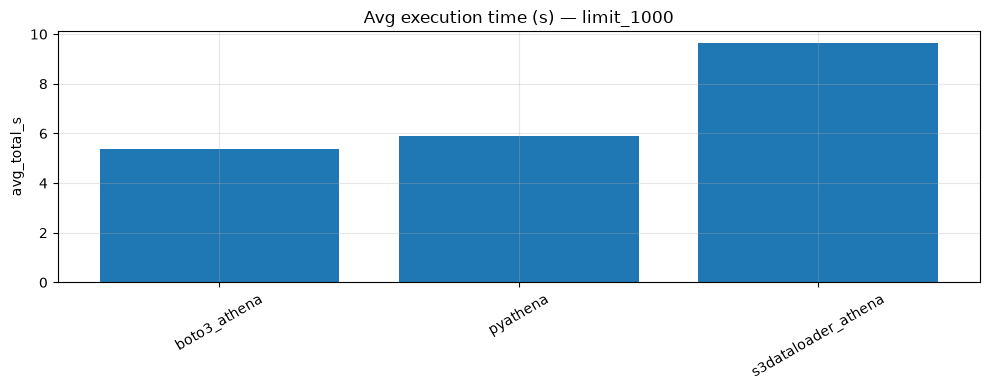

Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/chart_limit_1000_avg_total_s.png


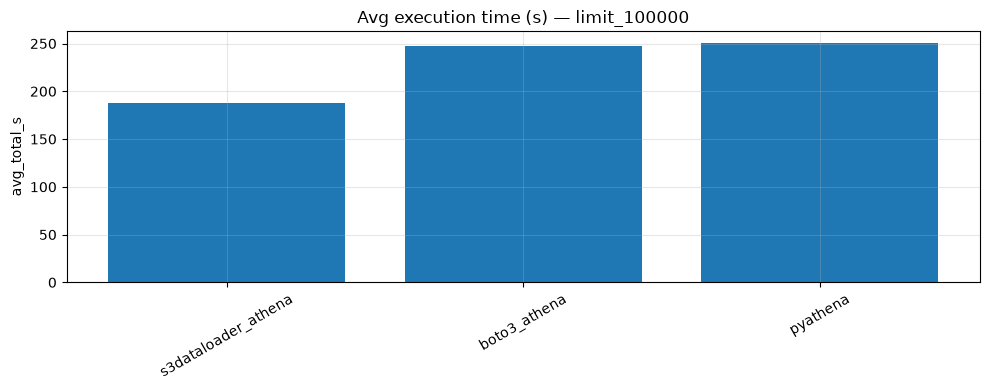

Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/chart_limit_100000_avg_total_s.png


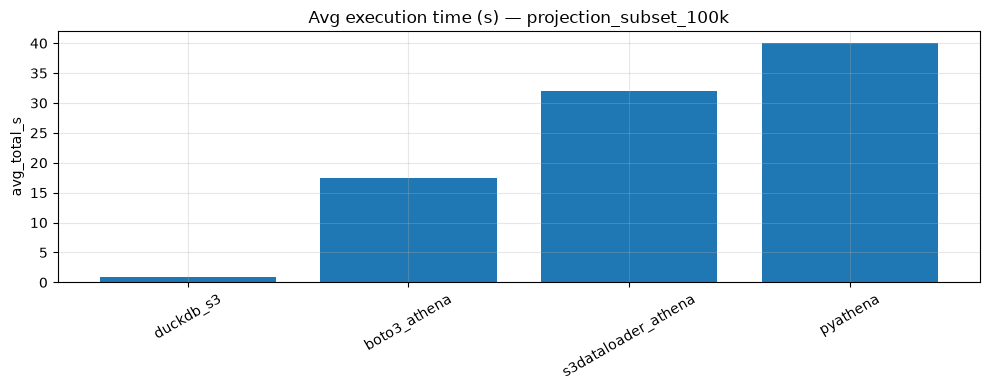

Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/chart_projection_subset_100k_avg_total_s.png


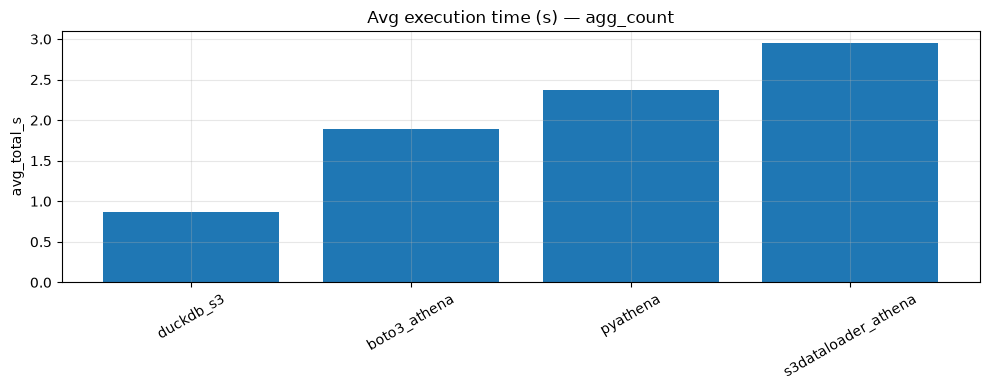

Saved /Users/lekhanigam/RM Feature Analysis/benchmark_results/chart_agg_count_avg_total_s.png


library,boto3_athena,duckdb_s3,pyathena,s3dataloader_athena
scenario,,,,
agg_count,2.187551,1.0,2.749706,3.418894
agg_distinct_visitor,2.055950,1.0,2.973563,3.434248
agg_minmax,1.989705,1.0,2.275250,2.956036
chunk_default_200000,28.894167,1.0,34.747745,4.718366
chunk_size_10000,6.426017,1.0,8.774629,1.910386
chunk_size_100000,13.200195,NaN,7.793774,1.000000
chunk_size_50000,20.096733,1.0,24.436761,3.234805
filter_date_range,22.953666,1.0,30.928917,4.328967
full_table_window,1.000000,NaN,1.236321,1.291388


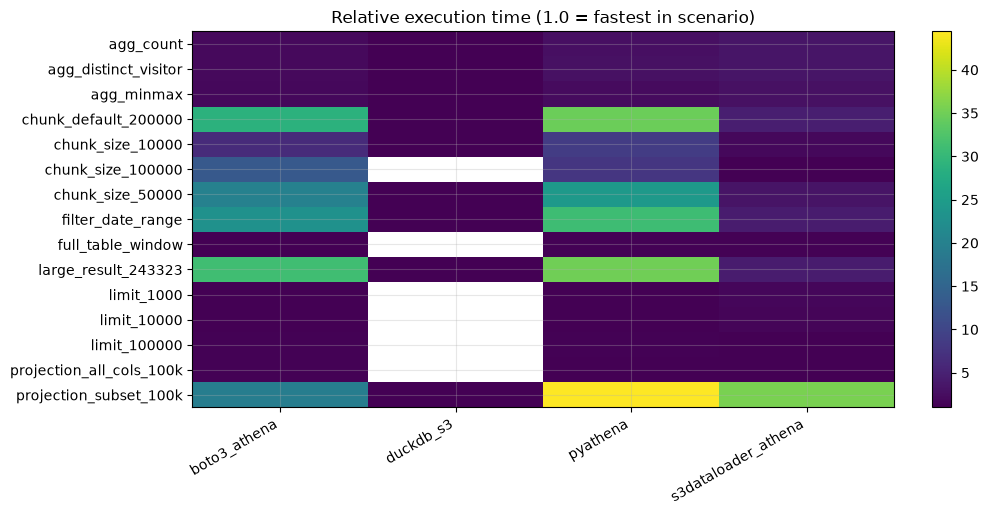

In [21]:
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

def bar_compare(scenario: str, metric: str = "avg_total_s", title: str | None = None):
    sub = summary[summary["scenario"] == scenario].sort_values(metric)
    if sub.empty:
        print("No data for", scenario)
        return
    fig, ax = plt.subplots()
    ax.bar(sub["library"], sub[metric])
    ax.set_ylabel(metric)
    ax.set_title(title or f"{metric} — {scenario}")
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    out = RESULTS_DIR / f"chart_{scenario}_{metric}.png"
    fig.savefig(out, dpi=120)
    plt.show()
    print("Saved", out)

# Representative charts
for sc in [
    "limit_1000",
    "limit_100000",
    "projection_subset_100k",
    "agg_count",
]:
    if sc in set(summary.scenario):
        bar_compare(sc, "avg_total_s", f"Avg execution time (s) — {sc}")

# Relative speed heatmap-like table chart for overall
pivot = summary.pivot_table(index="scenario", columns="library", values="relative_x")
display(pivot)

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(pivot))))
im = ax.imshow(pivot.fillna(np.nan).values, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_title("Relative execution time (1.0 = fastest in scenario)")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "chart_relative_heatmap.png", dpi=120)
plt.show()

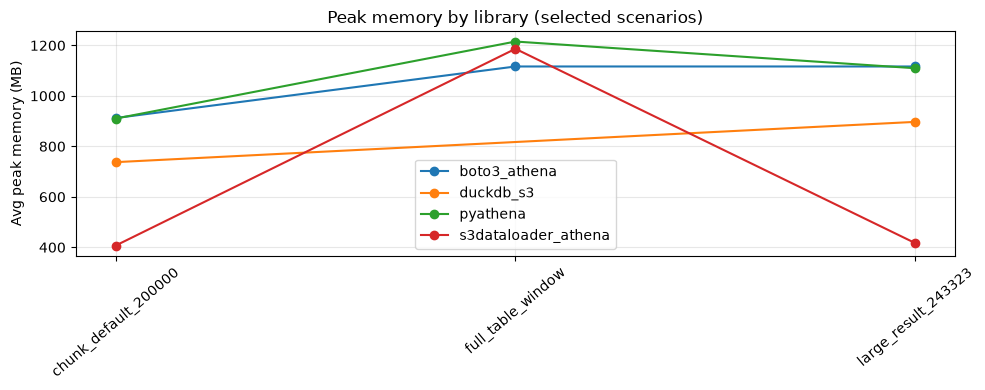

In [22]:
# Memory comparison on large / full scenarios
mem_sc = [s for s in summary.scenario.unique() if s.startswith("large_result") or s.startswith("full_table") or s.startswith("chunk_default")]
sub = summary[summary.scenario.isin(mem_sc)]
if not sub.empty:
    fig, ax = plt.subplots()
    for lib, g in sub.groupby("library"):
        ax.plot(g["scenario"], g["avg_peak_mem_mb"], marker="o", label=lib)
    ax.set_ylabel("Avg peak memory (MB)")
    ax.set_title("Peak memory by library (selected scenarios)")
    ax.tick_params(axis="x", rotation=40)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "chart_memory.png", dpi=120)
    plt.show()

## 11. Final analysis (evidence-based)

In [23]:
overall = ranks[ranks["category"] == "overall"].sort_values("rank")
display(overall)

fastest_overall = overall.iloc[0]["library"] if not overall.empty else None

# category winners
winners = (
    ranks.sort_values(["category", "rank"])
    .groupby("category", as_index=False)
    .first()[["category", "library", "mean_avg_s", "mean_mem"]]
)
display(winners)

# DX notes (static, not timed)
dx = pd.DataFrame([
    {"library": "s3dataloader_athena", "dx": "One API, retries, env config; already in product"},
    {"library": "pyathena", "dx": "DBAPI/SQLAlchemy/async/Polars; easy to misconfigure cursor"},
    {"library": "boto3_athena", "dx": "Full control, verbose boilerplate"},
    {"library": "duckdb_s3", "dx": "Great local SQL UX; S3 GET risk on large scans"},
    {"library": "metabase", "dx": "BI-oriented; row caps; extra hop"},
])
display(dx)

analysis = {
    "fastest_overall": fastest_overall,
    "winners_by_category": winners.to_dict(orient="records"),
    "window": {"start": BENCH_START, "end": BENCH_END, "rows": int(WINDOW_ROWS)},
    "active_libraries": list(adapters),
    "recommendation_rule": (
        "Prefer the library with best overall rank among Athena-backed adapters "
        "(s3dataloader_athena / pyathena / boto3_athena) for production defaults; "
        "treat duckdb_s3 as ad-hoc only if it wins speed but risks GET pressure; "
        "do not choose metabase if it fails, caps rows, or ranks last."
    ),
}

# Explicit recommendation text from numbers
athena_libs = [l for l in overall["library"] if l in {"s3dataloader_athena", "pyathena", "boto3_athena"}]
best_athena = None
for _, row in overall.iterrows():
    if row["library"] in {"s3dataloader_athena", "pyathena", "boto3_athena"}:
        best_athena = row["library"]
        break

print("\n========== FINAL RECOMMENDATION ==========")
print(f"Fastest overall (all adapters): {fastest_overall}")
print(f"Best Athena-backed adapter:     {best_athena}")
print("Category winners:")
print(winners.to_string(index=False))
print("\nDefault for s3DataLoader:")
if best_athena == "s3dataloader_athena":
    print("→ Keep/confirm Athena engine (awswrangler) as the production default.")
elif best_athena:
    print(f"→ Consider adopting patterns from {best_athena} or wrapping it; re-check product fit.")
else:
    print("→ Insufficient Athena-backed results; re-run after fixing failures.")
print("DuckDB: use only if this run shows clear wins on small/medium AND ops accepts S3 GET risk.")
print("Metabase: not a loader default unless it unexpectedly dominated (check row counts for caps).")
print("==========================================")

with open(RESULTS_DIR / "final_analysis.json", "w") as f:
    json.dump(analysis, f, indent=2, default=str)
print("Wrote", RESULTS_DIR / "final_analysis.json")

,library,mean_avg_s,mean_mem,scenarios,rank,category
23,duckdb_s3,9.735693,266.567800,9,1,overall
24,s3dataloader_athena,99.234842,232.454979,15,2,overall
25,boto3_athena,203.127285,368.358905,15,3,overall
26,pyathena,213.819978,389.892665,15,4,overall


,category,library,mean_avg_s,mean_mem
0,aggregations,duckdb_s3,0.885823,4.158243
1,chunked,duckdb_s3,22.222008,372.276554
2,filtered,duckdb_s3,5.555903,359.979953
3,large,duckdb_s3,11.842124,896.957563
4,medium_ish,duckdb_s3,3.227811,186.424122
5,overall,duckdb_s3,9.735693,266.567800
6,small_limits,s3dataloader_athena,77.906268,182.362114


,library,dx
0,s3dataloader_athena,"One API, retries, env config; already in product"
1,pyathena,DBAPI/SQLAlchemy/async/Polars; easy to misconf...
2,boto3_athena,"Full control, verbose boilerplate"
3,duckdb_s3,Great local SQL UX; S3 GET risk on large scans
4,metabase,BI-oriented; row caps; extra hop



========== FINAL RECOMMENDATION ==========
Fastest overall (all adapters): duckdb_s3
Best Athena-backed adapter:     s3dataloader_athena
Category winners:
    category             library  mean_avg_s   mean_mem
aggregations           duckdb_s3    0.885823   4.158243
     chunked           duckdb_s3   22.222008 372.276554
    filtered           duckdb_s3    5.555903 359.979953
       large           duckdb_s3   11.842124 896.957563
  medium_ish           duckdb_s3    3.227811 186.424122
     overall           duckdb_s3    9.735693 266.567800
small_limits s3dataloader_athena   77.906268 182.362114

Default for s3DataLoader:
→ Keep/confirm Athena engine (awswrangler) as the production default.
DuckDB: use only if this run shows clear wins on small/medium AND ops accepts S3 GET risk.
Metabase: not a loader default unless it unexpectedly dominated (check row counts for caps).
Wrote /Users/lekhanigam/RM Feature Analysis/benchmark_results/final_analysis.json
